# Seattle Weather Classification & Next-Day Prediction

This project looks at historical Seattle weather data to build and test machine-learning models for two related tasks:

1. Same-day weather classification: classify the observed weather condition using precipitation, temperature, and wind measurements.
2. Next-day weather prediction: predict the next day’s weather condition using only information from previous days.

The analysis looks beyond just headline accuracy. Since the target classes are imbalanced, model performance is measured using balanced accuracy, macro-F1, per-class precision and recall, as well as confusion matrices and feature importance.

Project workflow

* inspect data quality and class balance;
* explore weather patterns over time;
* build an XGBoost baseline model;
* compare XGBoost with alternative classifiers;
* account for class imbalance using class-aware evaluation and weighting;
* tune XGBoost using macro-F1;
* interpret model behaviour using feature importance and confusion matrices;
* extend the analysis into a true next-day prediction problem using lagged features and chronological validation;
* summarise limitations and future improvements.


In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score, classification_report,
    ConfusionMatrixDisplay
)
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

pd.set_option("display.max_columns", None)
RANDOM_STATE = 42

# Load the Seattle weather dataset from my local Downloads folder.
DATA_PATH = r"C:\Users\ayomi\Downloads\seattle-weather.csv"

raw_df = pd.read_csv(DATA_PATH)
raw_df["date"] = pd.to_datetime(raw_df["date"])
raw_df.head()

,date,precipitation,temp_max,temp_min,wind,weather
0,2012-01-01,0.0,12.8,5.0,4.7,drizzle
1,2012-01-02,10.9,10.6,2.8,4.5,rain
2,2012-01-03,0.8,11.7,7.2,2.3,rain
3,2012-01-04,20.3,12.2,5.6,4.7,rain
4,2012-01-05,1.3,8.9,2.8,6.1,rain


## Data quality and exploratory analysis

Before modelling, inspect the dataset structure, missing values, duplicates and target distribution. Class balance matters because an apparently high overall accuracy can hide weak performance on rare weather classes.

In [ ]:
print(f"Rows: {len(raw_df):,}")
print(f"Columns: {raw_df.shape[1]}")
print(f"Date range: {raw_df['date'].min().date()} to {raw_df['date'].max().date()}")
print(f"Duplicate rows: {raw_df.duplicated().sum()}")

quality = pd.DataFrame({
    "dtype": raw_df.dtypes.astype(str),
    "missing": raw_df.isna().sum(),
    "unique": raw_df.nunique()
})
display(quality)

class_counts = raw_df["weather"].value_counts().to_frame("count")
class_counts["percent"] = (class_counts["count"] / len(raw_df) * 100).round(2)
display(class_counts)

Rows: 1,461
Columns: 6
Date range: 2012-01-01 to 2015-12-31
Duplicate rows: 0


,dtype,missing,unique
date,datetime64[ns],0,1461
precipitation,float64,0,111
temp_max,float64,0,67
temp_min,float64,0,55
wind,float64,0,79
weather,object,0,5


,count,percent
weather,,
rain,641,43.87
sun,640,43.81
fog,101,6.91
drizzle,53,3.63
snow,26,1.78


### Data quality

The dataset contains 1,461 daily observations from 1 January 2012 to 31 December 2015, with six variables and no missing values or duplicate rows. The target is clearly imbalanced: rain (43.87%) and sun (43.81%) dominate, while fog (6.91%), drizzle (3.63%), and snow (1.78%) are much less frequent. This means overall accuracy can be misleading, so later sections also use balanced accuracy, macro-F1, and per-class precision/recall.


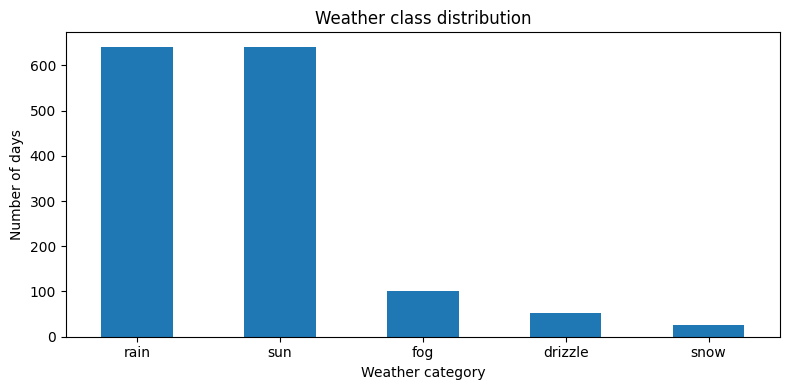

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
raw_df["weather"].value_counts().plot(kind="bar", ax=ax)
ax.set_title("Weather class distribution")
ax.set_xlabel("Weather category")
ax.set_ylabel("Number of days")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

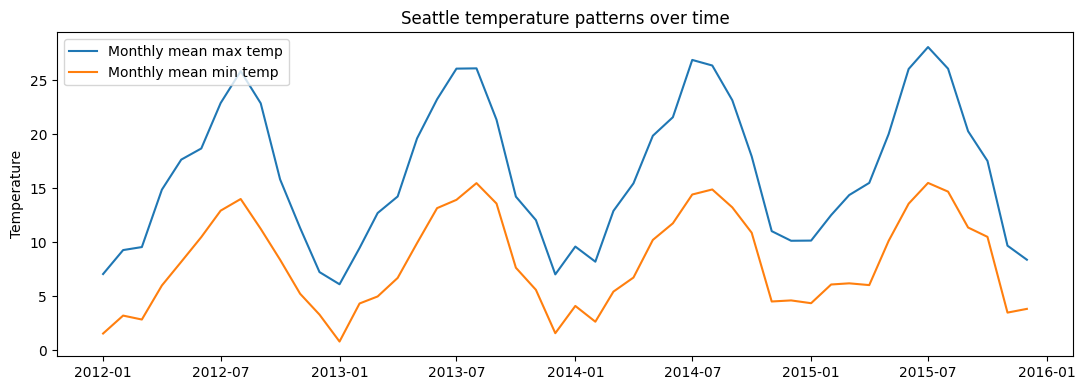

In [ ]:
monthly = (
    raw_df.set_index("date")[["temp_max", "temp_min", "precipitation", "wind"]]
    .resample("MS")
    .mean()
)
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(monthly.index, monthly["temp_max"], label="Monthly mean max temp")
ax.plot(monthly.index, monthly["temp_min"], label="Monthly mean min temp")
ax.set_title("Seattle temperature patterns over time")
ax.set_ylabel("Temperature")
ax.legend()
plt.tight_layout()
plt.show()

### Exploratory analysis

The exploratory plots are used to understand the distribution of the weather classes and how temperature, precipitation, and wind change over time. The strong dominance of rain and sun confirms the class-imbalance issue identified during the quality checks. Seasonal variation in temperature and precipitation also supports treating the data as time-ordered when building a genuine forecasting model.


Same-day weather classification

The first modeling task predicts today’s weather using precipitation, maximum and minimum temperatures, and wind speed.

To ensure a fair evaluation, the data is split with stratification so each weather class appears in both the training and test sets in the same proportion. Tree-based models use the original numerical features without scaling.

The modeling process involves:

1. an XGBoost baseline;
2. comparison with a naive baseline and Random Forest;
3. class-aware evaluation using macro-F1 and balanced accuracy;
4. class weighting for XGBoost;
5. hyperparameter tuning using macro-F1 rather than accuracy alone.


In [ ]:
classification_df = raw_df.copy()
label_encoder = LabelEncoder()
classification_df["weather_code"] = label_encoder.fit_transform(classification_df["weather"])

features = ["precipitation", "temp_max", "temp_min", "wind"]
X = classification_df[features]
y = classification_df["weather_code"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Classes:", dict(enumerate(label_encoder.classes_)))

Training rows: 1168
Test rows: 293
Classes: {0: 'drizzle', 1: 'fog', 2: 'rain', 3: 'snow', 4: 'sun'}


In [ ]:
# Baseline XGBoost model
baseline_xgb = XGBClassifier(
    random_state=RANDOM_STATE,
    eval_metric="mlogloss"
)
baseline_xgb.fit(X_train, y_train)
baseline_pred = baseline_xgb.predict(X_test)

print("Baseline XGBoost accuracy:", round(accuracy_score(y_test, baseline_pred), 3))
print("Baseline balanced accuracy:", round(balanced_accuracy_score(y_test, baseline_pred), 3))
print("Baseline macro-F1:", round(f1_score(y_test, baseline_pred, average="macro", zero_division=0), 3))
print()
print(classification_report(
    y_test,
    baseline_pred,
    target_names=label_encoder.classes_,
    zero_division=0
))


Baseline XGBoost accuracy: 0.799
Baseline balanced accuracy: 0.483
Baseline macro-F1: 0.493

              precision    recall  f1-score   support

     drizzle       0.10      0.09      0.10        11
         fog       0.21      0.15      0.18        20
        rain       0.95      0.91      0.93       129
        snow       0.50      0.40      0.44         5
         sun       0.78      0.86      0.82       128

    accuracy                           0.80       293
   macro avg       0.51      0.48      0.49       293
weighted avg       0.79      0.80      0.79       293



### Baseline XGBoost model

I used XGBoost as the first supervised learning model because it performs well on structured tabular data and can capture non-linear relationships between weather variables.

The baseline establishes a reference point before class weighting and hyperparameter optimisation. Performance is assessed using accuracy, balanced accuracy and macro-F1, together with per-class precision and recall. This makes it possible to see whether a model performs well across all weather categories rather than only on the dominant rain and sun classes.


In [ ]:
def evaluate_model(name, model, X_test, y_test):
    pred = model.predict(X_test)
    return {
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "balanced_accuracy": balanced_accuracy_score(y_test, pred),
        "macro_f1": f1_score(y_test, pred, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_test, pred, average="weighted", zero_division=0),
    }

models = {}
results = []

# Naive baseline: always predicts the most frequent class.
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
models["Dummy baseline"] = dummy
results.append(evaluate_model("Dummy baseline", dummy, X_test, y_test))

rf = RandomForestClassifier(
    n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE
)
rf.fit(X_train, y_train)
models["Random Forest"] = rf
results.append(evaluate_model("Random Forest", rf, X_test, y_test))

weights = compute_sample_weight(class_weight="balanced", y=y_train)
xgb = XGBClassifier(
    n_estimators=200, max_depth=4, learning_rate=0.05,
    subsample=0.9, colsample_bytree=0.9, random_state=RANDOM_STATE,
    eval_metric="mlogloss"
)
xgb.fit(X_train, y_train, sample_weight=weights)
models["Weighted XGBoost"] = xgb
results.append(evaluate_model("Weighted XGBoost", xgb, X_test, y_test))

comparison = pd.DataFrame(results).set_index("model").sort_values("macro_f1", ascending=False)
display(comparison.round(3))

,accuracy,balanced_accuracy,macro_f1,weighted_f1
model,,,,
Random Forest,0.816,0.474,0.505,0.797
Weighted XGBoost,0.706,0.530,0.505,0.752
Dummy baseline,0.440,0.200,0.122,0.269


### Model comparison

I compared majority-class baseline with Random Forest and class-weighted XGBoost using accuracy, balanced accuracy, macro-F1 and weighted-F1.

Random Forest achieved the strongest overall accuracy, while weighted XGBoost produced better balanced accuracy. This shows an important modelling trade-off: the model with the highest overall accuracy is not always the model that treats rare classes most evenly. For an imbalanced multiclass problem, both perspectives are important when selecting a final model.


In [ ]:
# Tune XGBoost for macro-F1 rather than accuracy.
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [3, 5],
    "learning_rate": [0.03, 0.1],
    "gamma": [0, 1],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
tuned_xgb = GridSearchCV(
    estimator=XGBClassifier(random_state=RANDOM_STATE, eval_metric="mlogloss"),
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=0
)
tuned_xgb.fit(X_train, y_train, sample_weight=weights)

print("Best parameters:", tuned_xgb.best_params_)
print("Best CV macro-F1:", round(tuned_xgb.best_score_, 3))

tuned_pred = tuned_xgb.predict(X_test)
print("Test accuracy:", round(accuracy_score(y_test, tuned_pred), 3))
print("Test balanced accuracy:", round(balanced_accuracy_score(y_test, tuned_pred), 3))
print("Test macro-F1:", round(f1_score(y_test, tuned_pred, average="macro", zero_division=0), 3))
print()
print(classification_report(
    y_test, tuned_pred, target_names=label_encoder.classes_, zero_division=0
))

Best parameters: {'gamma': 1, 'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 100}
Best CV macro-F1: 0.594
Test accuracy: 0.683
Test balanced accuracy: 0.583
Test macro-F1: 0.479

              precision    recall  f1-score   support

     drizzle       0.07      0.09      0.08        11
         fog       0.19      0.60      0.29        20
        rain       0.99      0.84      0.91       129
        snow       0.31      0.80      0.44         5
         sun       0.81      0.59      0.68       128

    accuracy                           0.68       293
   macro avg       0.47      0.58      0.48       293
weighted avg       0.81      0.68      0.73       293



### Tuning for macro-F1

I tuned XGBoost using macro-F1 rather than accuracy to ensure each weather class had equal weight in model selection. The best setup was gamma = 1, learning_rate = 0.03, max_depth = 3, and n_estimators = 100. Test accuracy dropped to 68.3%, but balanced accuracy increased to 58.3%. Recall for minority classes improved a lot, reaching 60% for fog and 80% for snow. This shows that lower overall accuracy can still mean a more balanced classifier.

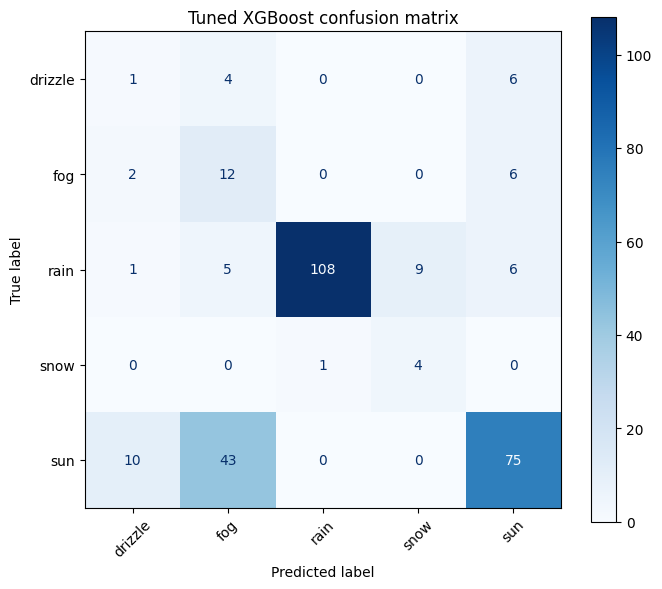

In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, tuned_pred, display_labels=label_encoder.classes_,
    cmap="Blues", xticks_rotation=45, ax=ax
)
ax.set_title("Tuned XGBoost confusion matrix")
plt.tight_layout()
plt.show()

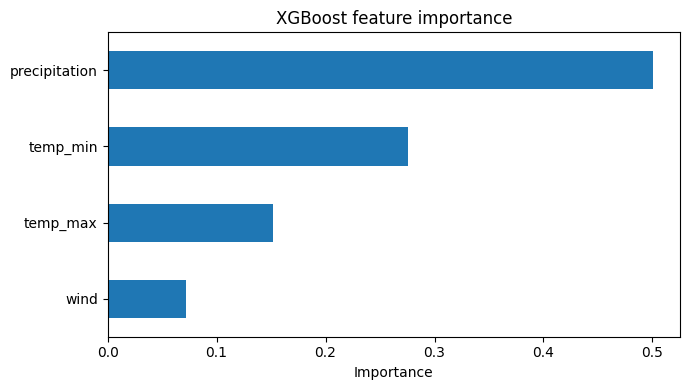

,importance
precipitation,0.500251
temp_min,0.275381
temp_max,0.152029
wind,0.072340


In [ ]:
best_xgb = tuned_xgb.best_estimator_
importance = pd.Series(best_xgb.feature_importances_, index=features).sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
importance.plot(kind="barh", ax=ax)
ax.set_title("XGBoost feature importance")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

display(importance.sort_values(ascending=False).to_frame("importance"))

### Model interpretation

I added Feature-importance analysis to make the tuned XGBoost model more interpretable. This helps identify which meteorological variables contribute most to the classification decisions and provides a check that the model is relying on meaningful weather information rather than functioning only as a black box.


## Next-day weather prediction

A proper forecast relies on information available before the day being predicted. Here, I predicted the next day's weather category using weather data from previous days.

Key steps to ensure accuracy:
- Data is arranged in chronological order.
- The prediction target is moved to the following day.
- Today's observed weather is used as a predictor for tomorrow.
- Lag and rolling features use only past observations.
- The test set consists of the last 20% of the timeline, rather than a random sample.

This task is more challenging than same-day classification, so lower performance metrics are expected. However, it is methodologically closer to real forecasting.

In [ ]:
forecast_df = raw_df.sort_values("date").copy()
forecast_df["target_weather"] = forecast_df["weather"].shift(-1)

base_features = ["precipitation", "temp_max", "temp_min", "wind"]

# Lag features: observations from 1, 2 and 3 days ago.
for lag in [1, 2, 3]:
    for col in base_features:
        forecast_df[f"{col}_lag{lag}"] = forecast_df[col].shift(lag)

# Rolling statistics use shift(1), so the target day's measurements never leak into features.
for col in base_features:
    forecast_df[f"{col}_roll3_mean"] = forecast_df[col].shift(1).rolling(3).mean()

# Tomorrow's calendar position is known in advance.
next_day = forecast_df["date"] + pd.Timedelta(days=1)
forecast_df["next_month"] = next_day.dt.month
forecast_df["next_dayofyear"] = next_day.dt.dayofyear

# Today's observed weather is also information that would be known when forecasting tomorrow.
# One-hot encoding avoids imposing a false ordinal relationship between weather labels.
forecast_df = pd.get_dummies(forecast_df, columns=["weather"], prefix="today_weather", dtype=int)

forecast_df = forecast_df.dropna().reset_index(drop=True)
forecast_encoder = LabelEncoder()
forecast_df["target_code"] = forecast_encoder.fit_transform(forecast_df["target_weather"])

forecast_features = [c for c in forecast_df.columns if "_lag" in c or "_roll3_mean" in c] + [
    "next_month", "next_dayofyear"
] + [c for c in forecast_df.columns if c.startswith("today_weather_")]

split_idx = int(len(forecast_df) * 0.8)
train_f = forecast_df.iloc[:split_idx]
test_f = forecast_df.iloc[split_idx:]

X_train_f = train_f[forecast_features]
y_train_f = train_f["target_code"]
X_test_f = test_f[forecast_features]
y_test_f = test_f["target_code"]

print("Forecast training period:", train_f["date"].min().date(), "to", train_f["date"].max().date())
print("Forecast test period:", test_f["date"].min().date(), "to", test_f["date"].max().date())
print("Forecast feature count:", len(forecast_features))

Forecast training period: 2012-01-04 to 2015-03-13
Forecast test period: 2015-03-14 to 2015-12-30
Forecast feature count: 23


### Converting classification into forecasting

The original model classified the weather using measurements from the same day, which is not a true forecast. This extension creates a next-day target, orders the data chronologically, and derives lagged/rolling predictors from information available before the target day. The train/test split is also chronological so future observations are not leaked into model training.


In [ ]:
forecast_results = []

dummy_f = DummyClassifier(strategy="most_frequent")
dummy_f.fit(X_train_f, y_train_f)
forecast_results.append(evaluate_model("Dummy baseline", dummy_f, X_test_f, y_test_f))

rf_f = RandomForestClassifier(
    n_estimators=500, class_weight="balanced", min_samples_leaf=2,
    random_state=RANDOM_STATE
)
rf_f.fit(X_train_f, y_train_f)
forecast_results.append(evaluate_model("Random Forest", rf_f, X_test_f, y_test_f))

forecast_weights = compute_sample_weight(class_weight="balanced", y=y_train_f)
xgb_f = XGBClassifier(
    n_estimators=300, max_depth=4, learning_rate=0.03,
    subsample=0.9, colsample_bytree=0.9, random_state=RANDOM_STATE,
    eval_metric="mlogloss"
)
xgb_f.fit(X_train_f, y_train_f, sample_weight=forecast_weights)
forecast_results.append(evaluate_model("Weighted XGBoost", xgb_f, X_test_f, y_test_f))

forecast_comparison = pd.DataFrame(forecast_results).set_index("model").sort_values("macro_f1", ascending=False)
display(forecast_comparison.round(3))

,accuracy,balanced_accuracy,macro_f1,weighted_f1
model,,,,
Random Forest,0.640,0.380,0.369,0.612
Weighted XGBoost,0.627,0.406,0.335,0.630
Dummy baseline,0.373,0.250,0.136,0.203


### Next-day model comparison

In the actual forecasting task, Random Forest had the highest macro-F1 among the models, with 64.0% accuracy, 38.0% balanced accuracy, and a macro-F1 of 0.369. Weighted XGBoost had a slightly lower accuracy (62.7%) but a slightly higher balanced accuracy (40.6%). Both models performed much better than the dummy baseline. However, their lower scores compared to same-day classification suggest that predicting future weather is more challenging and realistic.




Best next-day model: Random Forest
              precision    recall  f1-score   support

     drizzle       0.00      0.00      0.00         7
         fog       0.25      0.06      0.10        31
        rain       0.62      0.72      0.66       109
        snow       0.00      0.00      0.00         0
         sun       0.69      0.74      0.71       145

    accuracy                           0.64       292
   macro avg       0.31      0.30      0.30       292
weighted avg       0.60      0.64      0.61       292



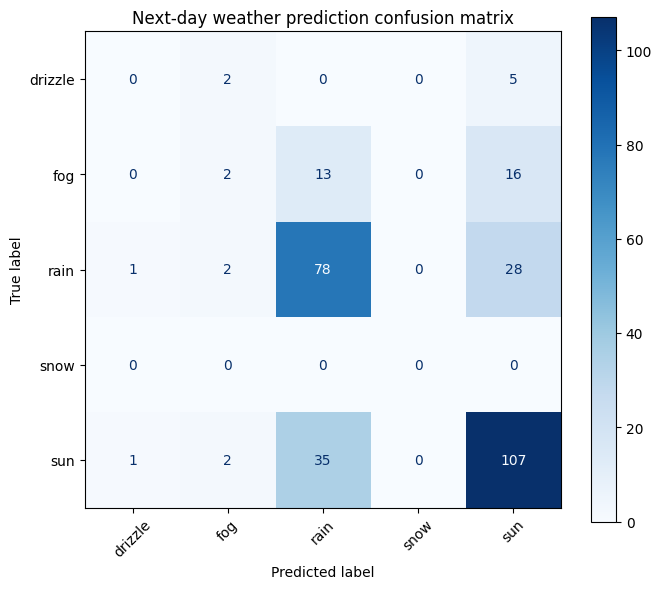

In [ ]:
# Inspect the strongest forecasting model by macro-F1.
best_forecast_name = forecast_comparison.index[0]
best_forecast_model = {
    "Dummy baseline": dummy_f,
    "Random Forest": rf_f,
    "Weighted XGBoost": xgb_f
}[best_forecast_name]

forecast_pred = best_forecast_model.predict(X_test_f)
print("Best next-day model:", best_forecast_name)
all_forecast_labels = np.arange(len(forecast_encoder.classes_))
print(classification_report(
    y_test_f, forecast_pred, labels=all_forecast_labels,
    target_names=forecast_encoder.classes_, zero_division=0
))

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test_f, forecast_pred, labels=all_forecast_labels,
    display_labels=forecast_encoder.classes_, cmap="Blues",
    xticks_rotation=45, ax=ax
)
ax.set_title("Next-day weather prediction confusion matrix")
plt.tight_layout()
plt.show()

### Forecast performance by class

Random Forest was the best model for next-day predictions. It gave the highest F1-scores for the main classes, about 0.66 for rain and 0.71 for sun. However, it struggled with rare classes such as drizzle and fog, and there were no snow events during the test period. These results show that class imbalance and a lack of rare-event data remain the main challenges to forecast quality.


## Conclusions and limitations

### Overall findings

This project demonstrates a complete machine learning workflow using Python, Pandas, scikit-learn, XGBoost, and Random Forest.

In the same-day classification task, the models performed well on the main rain and sun classes but struggled with less common classes such as drizzle, fog, and snow. Looking at accuracy alongside balanced accuracy and macro-F1 made it clear that one main metric isn’t enough for imbalanced data.

Using class weighting and tuning for macro-F1 helped the model better recognize some of the less common classes, striking a balance between overall accuracy and fair performance across all categories. Feature importance analysis helped explain which weather variables mattered most to the model’s choices.

The next-day prediction task was harder because the model could only use past data. To make the forecasting setup more realistic and avoid using future information in training, I used a chronological split.

Limitations

* The dataset is quite small and highly imbalanced.
* There aren’t enough examples of rare weather conditions to classify them reliably every time.
* The next-day model only uses the variables in this dataset. Adding more meteorological information could help it predict better. The project is designed as a machine-learning portfolio study rather than an operational weather forecasting system.

Future improvements

In the future, I could try longer lag windows, add more weather features, use resampling strategies, calibrate probabilities, apply time-series cross-validation, or test more advanced ensemble and sequence models.

